c       RMS error       Max error       synchronized
0.20    1.472e+01       5.251e+01       False
0.40    2.033e+01       5.497e+01       False
0.45    2.356e+01       2.356e+01       False
0.46    6.957e-07       1.099e-05       True
0.50    0.000e+00       0.000e+00       True
Literature local threshold: c > 0.90563 / 2 = 0.452815
Finite-time, single-initial-condition demonstration; not a global threshold.
Saved figures and results to: C:\Users\lenovo\lorenz_results


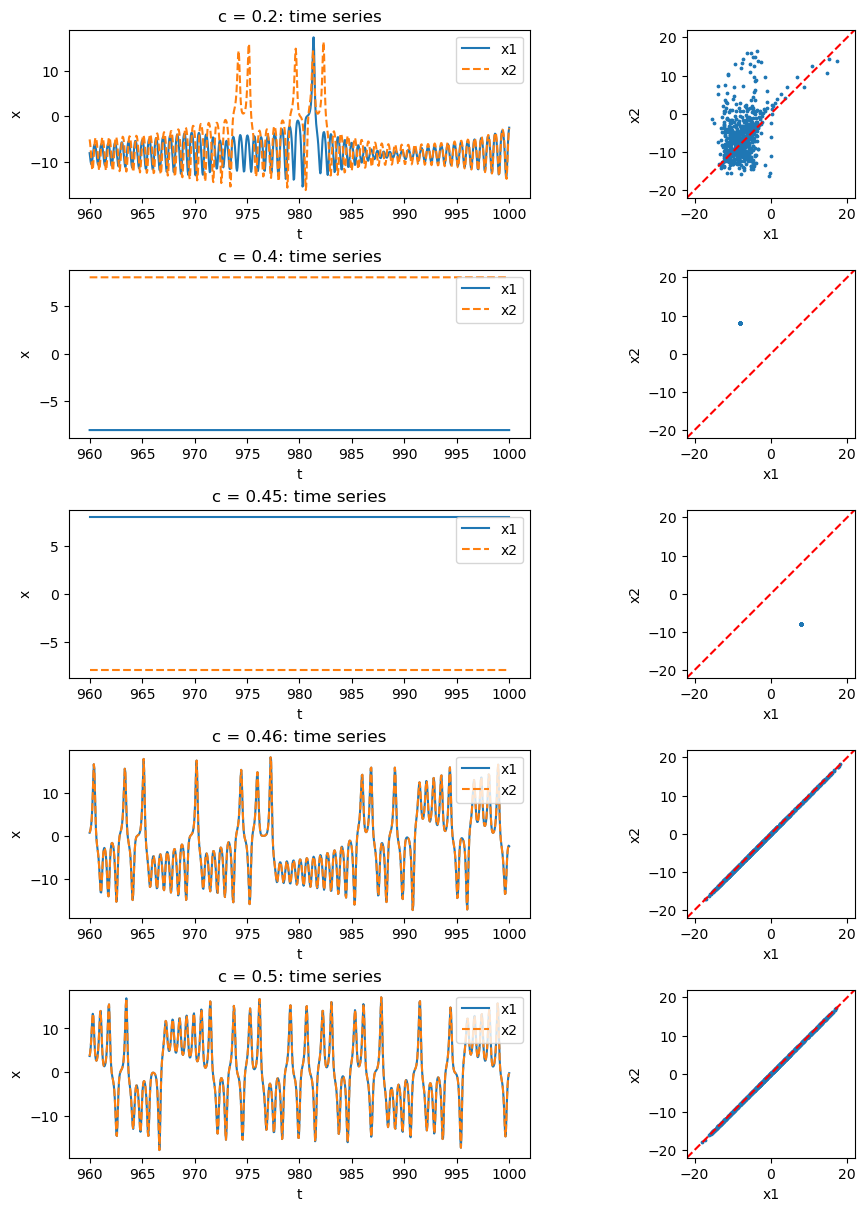

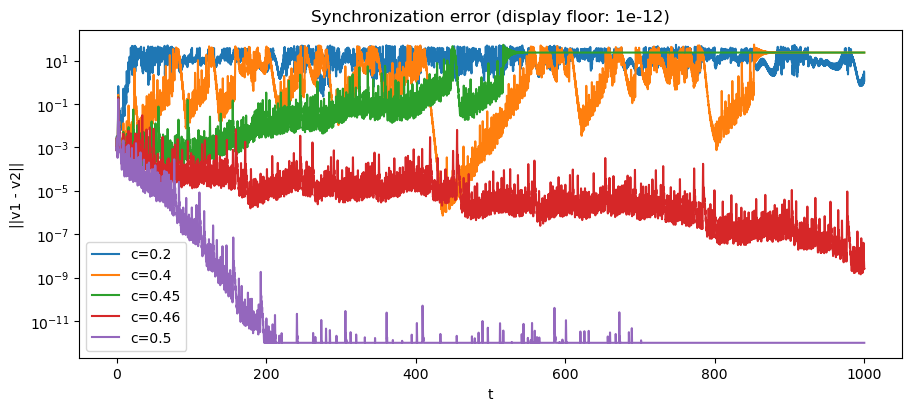

In [9]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


# 1. Parameter
COUPLINGS = [0.2, 0.4, 0.45, 0.46, 0.5]  # Coupling strength to compare
T = 1000.0                              # Points Expiration Date
TAIL = 200.0                            # Determine synchronization using the last 200 time units
OUTPUT_DT = 0.05                        # The interval for saving results, not the integration step.
SHOW_PLOTS = True                    


def coupled_lorenz(t, state, c):
    """Enter the current time, six state variables, and the coupling strength; return the derivatives of the six state variables."""
    x1, y1, z1, x2, y2, z2 = state
    sigma, rho, beta = 10.0, 28.0, 8.0 / 3.0

    # The first Lorenz system: the original equation + the effect of the second system on it.
    dx1 = sigma * (y1 - x1) + c * (x2 - x1)
    dy1 = x1 * (rho - z1) - y1 + c * (y2 - y1)
    dz1 = x1 * y1 - beta * z1 + c * (z2 - z1)

    # The second Lorenz system: the coupling direction is opposite, but the strength is still c.
    dx2 = sigma * (y2 - x2) + c * (x1 - x2)
    dy2 = x2 * (rho - z2) - y2 + c * (y1 - y2)
    dz2 = x2 * y2 - beta * z2 + c * (z1 - z2)
    return [dx1, dy1, dz1, dx2, dy2, dz2]


def main():
    # The first group's average initial values are located near the single-system attractor.
    center = np.array([-1.2663338511707862,
                       -1.6301185690947118, 16.24087486502361])
    # The initial distance between the two systems is 0.001, so you can't check synchronization using exactly the same initial values.
    difference = 0.001 * np.array([1.0, -2.0, 1.0]) / np.sqrt(6.0)
    initial = np.concatenate([center + difference / 2,
                              center - difference / 2])

    times = np.linspace(0.0, T, int(round(T / OUTPUT_DT)) + 1)
    fig, axes = plt.subplots(len(COUPLINGS), 2,
                             figsize=(10, 2.4 * len(COUPLINGS)),
                             squeeze=False, constrained_layout=True)
    fig_error, ax_error = plt.subplots(figsize=(9, 4), constrained_layout=True)
    rows = []
    print("c       RMS error       Max error       synchronized", flush=True)

    for row, c in enumerate(COUPLINGS):
        solution = solve_ivp(coupled_lorenz, (0.0, T), initial,
                             args=(c,), t_eval=times, method="DOP853",
                             rtol=1e-9, atol=1e-11, max_step=0.05)
        if not solution.success:
            raise RuntimeError(solution.message)

        # solution.y Each row corresponds to a variable, and each column corresponds to a point in time for the output.
        x1, y1, z1, x2, y2, z2 = solution.y
        error = np.sqrt((x1-x2)**2 + (y1-y2)**2 + (z1-z2)**2)
        tail_error = error[times >= T - TAIL]
        rms = np.sqrt(np.mean(tail_error**2))  
        maximum = np.max(tail_error)          
        synchronized = rms < 1e-4 and maximum < 1e-3
        rows.append([c, rms, maximum, int(synchronized)])
        print(f"{c:.2f}    {rms:.3e}       {maximum:.3e}       {synchronized}",
              flush=True)

        window = times >= T - 40.0
        axes[row, 0].plot(times[window], x1[window], label="x1")
        axes[row, 0].plot(times[window], x2[window], "--", label="x2")
        axes[row, 0].set(title=f"c = {c}: time series", xlabel="t", ylabel="x")
        axes[row, 0].legend(loc="upper right")


        axes[row, 1].scatter(x1[window], x2[window], s=3)
        axes[row, 1].plot([-22, 22], [-22, 22], "r--")
        axes[row, 1].set(xlabel="x1", ylabel="x2", xlim=(-22, 22), ylim=(-22, 22))
        axes[row, 1].set_aspect("equal")

        ax_error.semilogy(times, np.maximum(error, 1e-12), label=f"c={c}")

    ax_error.set(xlabel="t", ylabel="||v1 - v2||",
                 title="Synchronization error (display floor: 1e-12)")
    ax_error.legend()
    folder = Path.cwd() / "lorenz_results"
    folder.mkdir(parents=True, exist_ok=True)
    
    fig.savefig(folder / "simple_time_series.png", dpi=150)
    fig_error.savefig(folder / "simple_error.png", dpi=150)
    np.savetxt(folder / "simple_results.csv", rows, delimiter=",",
               header="c,rms_error,max_error,synchronized_1_yes_0_no", comments="")
    print("Literature local threshold: c > 0.90563 / 2 = 0.452815")
    print("Finite-time, single-initial-condition demonstration; not a global threshold.")
    print(f"Saved figures and results to: {folder}")
    if SHOW_PLOTS:
        plt.show()
    plt.close("all")

main()